Net(
  (fc1): Linear(in_features=2, out_features=1, bias=False)
)
[Parameter containing:
tensor([[ 1., -1.]], requires_grad=True)]
Epoch 0 - average loss: 39.334532
Epoch 1 - average loss: 80.625629
Epoch 2 - average loss: 37.829956
Epoch 3 - average loss: 75.121512
Epoch 4 - average loss: 37.674733
Epoch 5 - average loss: 74.591525
Epoch 6 - average loss: 37.395082
Epoch 7 - average loss: 74.140797
Epoch 8 - average loss: 37.116333
Epoch 9 - average loss: 73.694979
Epoch 10 - average loss: 36.840476
Epoch 11 - average loss: 73.252864
Epoch 12 - average loss: 36.567522
Epoch 13 - average loss: 72.814407
Epoch 14 - average loss: 36.297446
Epoch 15 - average loss: 72.379595
Epoch 16 - average loss: 36.030199
Epoch 17 - average loss: 71.948314
Epoch 18 - average loss: 35.765771
Epoch 19 - average loss: 71.520611
Epoch 20 - average loss: 35.504124
Epoch 21 - average loss: 71.096446
Epoch 22 - average loss: 35.245239
Epoch 23 - average loss: 70.675761
Epoch 24 - average loss: 34.989076
Epoc

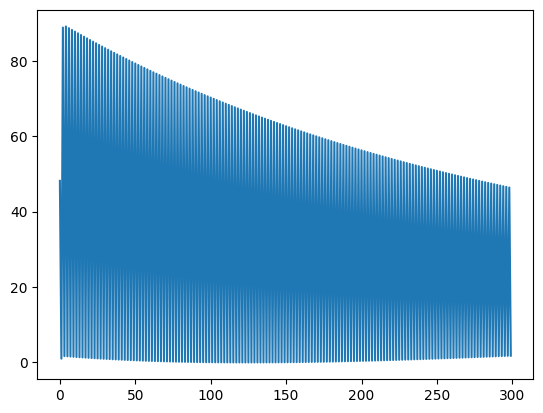

In [25]:
import torch
from torch.autograd import Variable
import torch.nn as nn
import torch.nn.functional as F

import torch.optim as optim
import matplotlib.pyplot as plt

class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc1 = nn.Linear(2,1,bias=False)
    def forward(self, x):
        x = self.fc1(x)
        return x

net = Net()
print(net)


net.fc1.weight = torch.nn.Parameter(torch.tensor([[1., -1.]], requires_grad=True))

print(list(net.parameters()))

#input = torch.randn(1,2)
#out = net(input)


criterion = nn.MSELoss()
#def criterion(out, label):
#    return ((label - out)**2).mean()


optimizer = optim.SGD(net.parameters(), lr=0.01, momentum=0.5)
#optimizer = optim.Adam(net.parameters(), lr=0.005)


data = torch.tensor([[1.,3.], [2.,6.], [3.,9.]], dtype=torch.float)
target = torch.tensor([[1.],[5.],[13.]], dtype=torch.float)

hist = []

############## SGD-based update ##############

for epoch in range(300):
    epoch_loss = 0.0

    for i in range(len(data)):
        optimizer.zero_grad()
        output = net(data[i])
        loss = criterion(output, target[i])
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    # Average loss across all data points for this epoch
    avg_loss = epoch_loss / len(data)
    hist.append(loss.item())

    print(f"Epoch {epoch} - average loss: {avg_loss:.6f}")

################################################

# ############## Batch GD based update ##############       
      
# for epoch in range(300):   
#     optimizer.zero_grad()
#     outputs = net(data)
#     loss = criterion(outputs, target)
#     loss.backward()
#     hist.append(loss.detach())
#     optimizer.step()
#     print("Epoch {} - loss: {}".format(epoch, loss))
# ####################################################

### Test the trained network ###
for i, current_data in enumerate(data):
    out = net(current_data)  
    print("when x = {}, y = {}".format(current_data, out))
    
plt.plot(hist, label = "training curve")